# NLP Network Installation

##Task1 - Sentiment Ananlysis

In [2]:
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, SimpleRNN, LSTM, Bidirectional, GRU

In [3]:
# Load the IMDB Dataset

vocab_size = 1000 # Top 10,000 words
maxlen = 200
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=vocab_size)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [4]:
# Pad sequence

x_train = pad_sequences(x_train, maxlen=maxlen)
x_test = pad_sequences(x_test, maxlen=maxlen)

In [5]:
# Model Builder Function

def builder_model(rnn_layer):
  model = Sequential()
  model.add(Embedding(vocab_size, 64, input_length=maxlen))
  model.add(rnn_layer)
  model.add(Dense(1, activation='sigmoid'))

  model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
  return model

In [7]:
# 1. Simple RNN Model

simple_rnn_model = builder_model(SimpleRNN(64))
simple_rnn_model.summary()
simple_rnn_model.fit(x_train, y_train, epochs=5, batch_size=128, validation_split=0.2)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - accuracy: 0.5871 - loss: 0.6660 - val_accuracy: 0.7190 - val_loss: 0.5545
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.7709 - loss: 0.4845 - val_accuracy: 0.7376 - val_loss: 0.5223
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.8147 - loss: 0.4161 - val_accuracy: 0.7844 - val_loss: 0.5277
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.7673 - loss: 0.4895 - val_accuracy: 0.6824 - val_loss: 0.5836
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.7918 - loss: 0.4543 - val_accuracy: 0.8030 - val_loss: 0.4490


In [8]:
# 2. LSTM Model

lstm_model = builder_model(LSTM(64))
lstm_model.summary()
lstm_model.fit(x_train, y_train, epochs=5, batch_size=128, validation_split=0.2)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.7120 - loss: 0.5564 - val_accuracy: 0.8200 - val_loss: 0.4209
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.8385 - loss: 0.3747 - val_accuracy: 0.8466 - val_loss: 0.3521
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.8508 - loss: 0.3526 - val_accuracy: 0.8444 - val_loss: 0.3637
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.8633 - loss: 0.3212 - val_accuracy: 0.8544 - val_loss: 0.3387
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.8683 - loss: 0.3058 - val_accuracy: 0.8506 - val_loss: 0.3466


In [9]:
# 3. Bi-directional

bidirectional_model = builder_model(Bidirectional(LSTM(64)))
bidirectional_model.summary()
bidirectional_model.fit(x_train, y_train, epochs=5, batch_size=128, validation_split=0.2)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - accuracy: 0.7210 - loss: 0.5414 - val_accuracy: 0.7770 - val_loss: 0.4878
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.8315 - loss: 0.3844 - val_accuracy: 0.8364 - val_loss: 0.3942
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.8503 - loss: 0.3470 - val_accuracy: 0.8530 - val_loss: 0.3455
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.8607 - loss: 0.3301 - val_accuracy: 0.8484 - val_loss: 0.3471
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.8685 - loss: 0.3113 - val_accuracy: 0.8400 - val_loss: 0.3662


In [11]:
# 4. Stacker Bar

stacker_model = Sequential()
stacker_model.add(Embedding(vocab_size, 64, input_length=maxlen))
stacker_model.add(LSTM(64, return_sequences=True))
stacker_model.add(LSTM(32))
stacker_model.add(Dense(1, activation='sigmoid'))

stacker_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
stacker_model.summary()
stacker_model.fit(x_train, y_train, epochs=5, batch_size=128, validation_split=0.2)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - accuracy: 0.7250 - loss: 0.5239 - val_accuracy: 0.8116 - val_loss: 0.4258
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.8466 - loss: 0.3587 - val_accuracy: 0.7816 - val_loss: 0.4488
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.8504 - loss: 0.3480 - val_accuracy: 0.8512 - val_loss: 0.3412
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.8605 - loss: 0.3249 - val_accuracy: 0.8500 - val_loss: 0.3410
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.8727 - loss: 0.3027 - val_accuracy: 0.8496 - val_loss: 0.3438


In [12]:
# 5. GRU

gru_model = builder_model(GRU(64))
gru_model.summary()
gru_model.fit(x_train, y_train, epochs=5, batch_size=128, validation_split=0.2)

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_6 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.6862 - loss: 0.5660 - val_accuracy: 0.8052 - val_loss: 0.4269
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.8183 - loss: 0.4095 - val_accuracy: 0.7816 - val_loss: 0.4721
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.8404 - loss: 0.3684 - val_accuracy: 0.8222 - val_loss: 0.4132
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.8539 - loss: 0.3406 - val_accuracy: 0.8498 - val_loss: 0.3543
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.8641 - loss: 0.3219 - val_accuracy: 0.8386 - val_loss: 0.3699


In [15]:
def evaluate_model(model, name):
  loss, accuracy = model.evaluate(x_test, y_test)
  print(f"{name} - Accuracy: {accuracy}, Loss: {loss:.4f}")

evaluate_model(simple_rnn_model, "Simple RNN")
evaluate_model(lstm_model, "LSTM")
evaluate_model(bidirectional_model, "Bi-directional LSTM")
evaluate_model(stacker_model, "Stacker LSTM")
evaluate_model(gru_model, "GRU")

782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8125 - loss: 0.4364
Simple RNN - Accuracy: 0.8124799728393555, Loss: 0.4364
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8529 - loss: 0.3383
LSTM - Accuracy: 0.8528800010681152, Loss: 0.3383
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8428 - loss: 0.3561
Bi-directional LSTM - Accuracy: 0.8428400158882141, Loss: 0.3561
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8586 - loss: 0.3292
Stacker LSTM - Accuracy: 0.8585600256919861, Loss: 0.3292
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8437 - loss: 0.3602
GRU - Accuracy: 0.8436800241470337, Loss: 0.3602


In [16]:
def predict_new_text(text, model, tokenizer, maxlen=200):
  tokenized_text = tokenizer.texts_to_sequences([text])
  if not tokenized_text:
    return "invalid input text"
  padded_text = pad_sequences(tokenized_text, maxlen=maxlen, padding='post')
  prediction = model.predict(padded_text)
  return "Positive" if prediction > 0.5 else "Negative"

In [28]:
from pygments.token import Token
from tensorflow.keras.preprocessing.text import Tokenizer
tokenizer = Tokenizer()

new_text = "I love the movie, it was fantastic!"
print(f"simple_rnn_model: {predict_new_text(new_text, simple_rnn_model, tokenizer)}")
print(f"lstm_model: {predict_new_text(new_text, lstm_model, tokenizer)}")
print(f"bidirectional_model: {predict_new_text(new_text, bidirectional_model, tokenizer)}")
print(f"stacker_model: {predict_new_text(new_text, stacker_model, tokenizer)}")
print(f"gru_model: {predict_new_text(new_text, gru_model, tokenizer)}")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
simple_rnn_model: Negative
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
lstm_model: Negative
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
bidirectional_model: Positive
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
stacker_model: Negative
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
gru_model: Positive


In [25]:
import matplotlib.pyplot as plt

def plot_loss(history, model_name):
  plt.figure(figsize=(10, 6))
  plt.plot(history.history['loss'], label='Training Loss')
  plt.plot(history.history['val_loss'], label='Validation Loss')
  plt.title(f'Loss Curve - {model_name}')
  plt.xlabel('Epoch')
  plt.ylabel('Loss')
  plt.legend()
  plt.show()



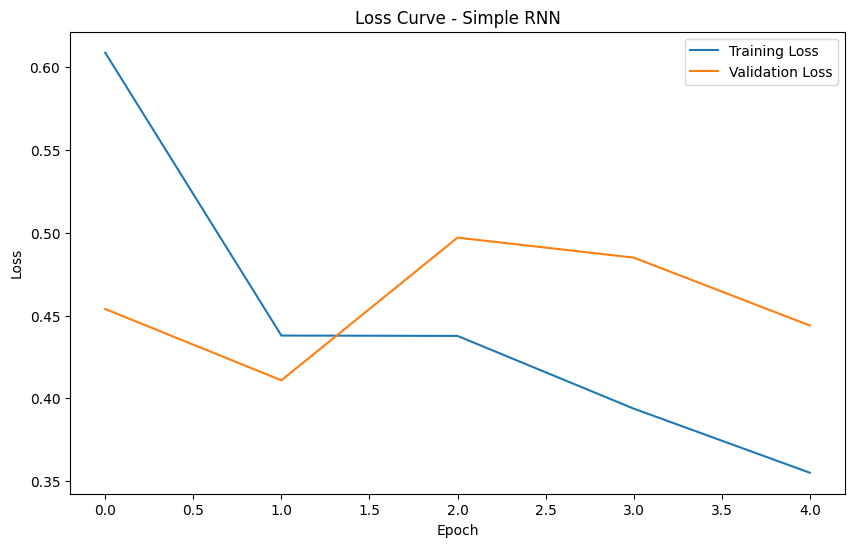

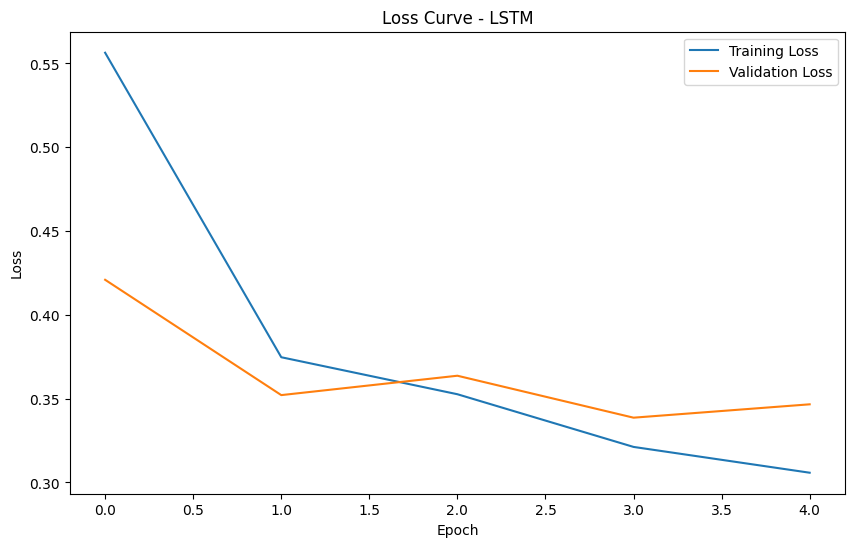

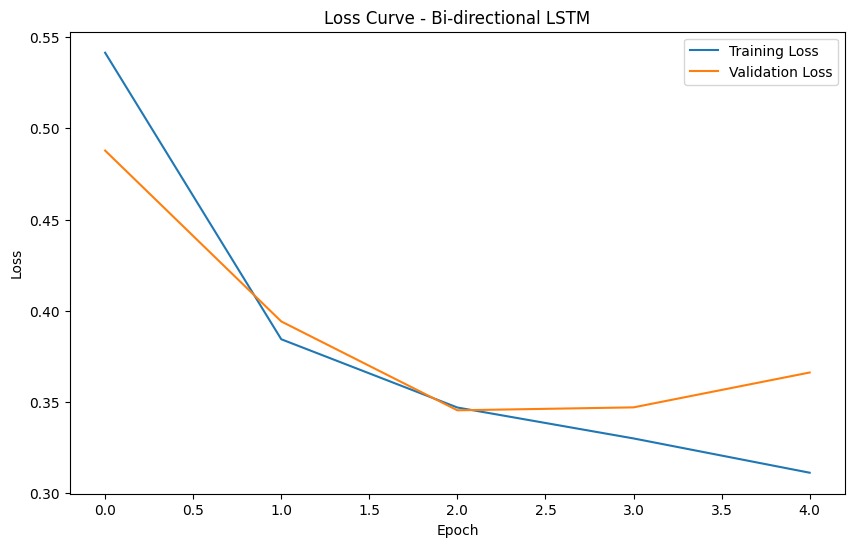

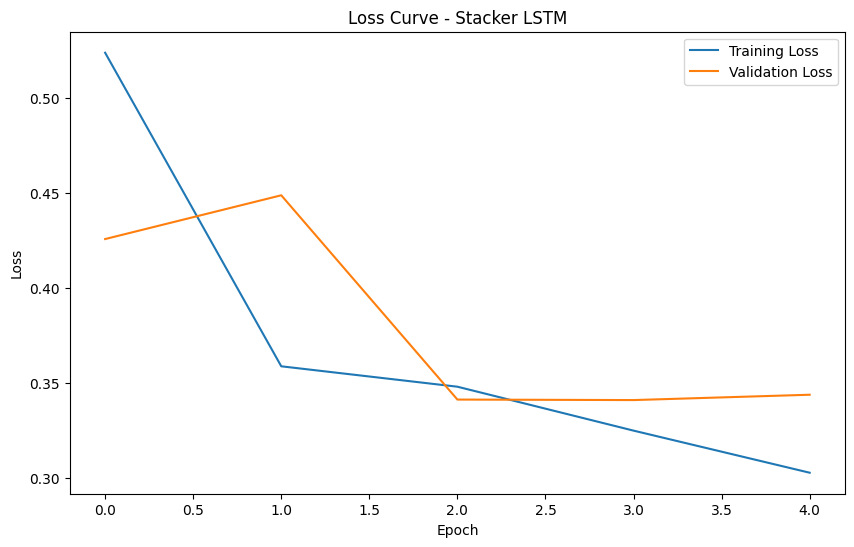

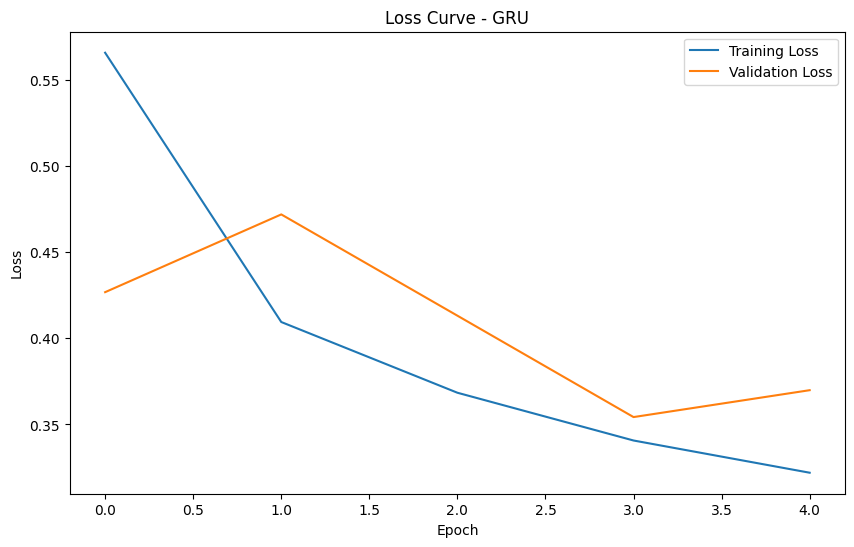

In [26]:
plot_loss(simple_rnn_model.history, "Simple RNN")
plot_loss(lstm_model.history, "LSTM")
plot_loss(bidirectional_model.history, "Bi-directional LSTM")
plot_loss(stacker_model.history, "Stacker LSTM")
plot_loss(gru_model.history, "GRU")